In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset saved after EDA.
df = pd.read_csv(
    r"D:\MASTERS\FOML\assignment\Project\Project@\ML-Health-Insurance\main\cleaned.csv"
)

# Preserve an unchanged copy.
original_df = df.copy(deep=True)

print("Dataset shape:", df.shape)

print("\nObservations by year:")
print(df["period"].value_counts().sort_index())

display(df.head())

Dataset shape: (162629, 42)

Observations by year:
period
2017    55999
2018    53555
2019    53075
Name: count, dtype: int64


C:\Users\AUM\AppData\Local\Temp\ipykernel_13720\33443563.py:7: DtypeWarning: Columns (5: date_lapse_insured, 7: date_lapse_policy) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,ID,ID_policy,ID_insured,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,year_effect_insured,year_lapse_insured,...,C_H,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C
0,1_2,1,2,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H1,99.0,85.0,18.0,52.0,59.0,4.0,14.0,96.0,C6
1,2_1,2,1,2017,1993-06-16,NaN,1993-06-16,NaN,1993,NaN,...,H6,100.0,94.0,26.0,11.0,85.0,7.0,1.0,100.0,C6
2,3_3,3,3,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3_5,3,5,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H6,99.0,81.0,32.0,34.0,69.0,9.0,4.0,98.0,C6
4,3_6,3,6,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H1,32.0,9.0,100.0,80.0,2.0,83.0,51.0,19.0,C4


In [3]:
# Identify chronologically inconsistent observations.
invalid_rows = (
    df["seniority_insured"] - df["age"] > 1
)

print("Observations to remove:", invalid_rows.sum())

print("\nRemovals by year:")
print(df.loc[invalid_rows, "period"].value_counts().sort_index())

# Remove the flagged observations.
df = df.loc[~invalid_rows].copy()

print("\nRemaining dataset shape:", df.shape)

print("\nRemaining observations by year:")
print(df["period"].value_counts().sort_index())

Observations to remove: 99

Removals by year:
period
2017    35
2018    34
2019    30
Name: count, dtype: int64

Remaining dataset shape: (162530, 42)

Remaining observations by year:
period
2017    55964
2018    53521
2019    53045
Name: count, dtype: int64


In [4]:
# Split by reporting year.
train_df = df.loc[df["period"] == 2017].copy()
val_df = df.loc[df["period"] == 2018].copy()
test_df = df.loc[df["period"] == 2019].copy()

print("Training — 2017:", train_df.shape)
print("Validation — 2018:", val_df.shape)
print("Testing — 2019:", test_df.shape)

Training — 2017: (55964, 42)
Validation — 2018: (53521, 42)
Testing — 2019: (53045, 42)


In [9]:
# Predictors for the model.
predictors = [
    "age",
    "gender",
    "seniority_insured",
    "seniority_policy",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "distribution_channel",
    "exposure_time",
    "n_insured_pc",
    "n_insured_mun",
    "n_insured_prov",
    "IICIMUN",
    "IICIPROV",
    "C_H",
    "C_GI",
    "C_II",
    "C_IE_P",
    "C_IE_S",
    "C_IE_T",
    "C_GE_P",
    "C_GE_S",
    "C_GE_T",
    "C_C"
]

# Separate predictors for each partition.
X_train = train_df[predictors].copy()
X_val = val_df[predictors].copy()
X_test = test_df[predictors].copy()

# Preserve original premiums for evaluation.
y_train = train_df["premium"].copy()
y_val = val_df["premium"].copy()
y_test = test_df["premium"].copy()

# Target used for model training.
y_train_log = np.log(y_train)

# Identify categorical and numerical predictors.
categorical_columns = [
    "gender",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "distribution_channel",
    "C_H",
    "C_C"
]

numerical_columns = [
    column for column in predictors
    if column not in categorical_columns
]

print("Total predictors:", len(predictors))
print("Numerical predictors:", len(numerical_columns))
print("Categorical predictors:", len(categorical_columns))

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nMissing values in training predictors:")
print(X_train.isna().sum())

Total predictors: 25
Numerical predictors: 17
Categorical predictors: 8

Training: (55108, 25)
Validation: (53521, 25)
Testing: (53045, 25)

Missing values in training predictors:
age                        0
gender                     0
seniority_insured          0
seniority_policy           0
type_policy                0
type_policy_dg             0
type_product               0
reimbursement              0
distribution_channel       0
exposure_time              0
n_insured_pc               0
n_insured_mun              0
n_insured_prov             0
IICIMUN                 1477
IICIPROV                   0
C_H                     1477
C_GI                    2194
C_II                    2194
C_IE_P                  2194
C_IE_S                  2194
C_IE_T                  2194
C_GE_P                  2194
C_GE_S                  2194
C_GE_T                  2194
C_C                     1331
dtype: int64


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

numerical_pipeline = Pipeline([
    ("scaling", StandardScaler()),
    ("imputation", KNNImputer(
        n_neighbors=5,
        add_indicator=True
    ))
])

numerical_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaling', ...), ('imputation', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto theoutput of the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear on themissing indicator even if there are missing values at transform/testtime.",True
,"missing_values missing_values: int, float, str, np.nan or None, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to np.nan, since `pd.NA` will be converted to np.nan.",nan
,"n_neighbors n_neighbors: int, default=5Number of neighboring samples to use for imputation.",5
,"weights weights: {'uniform', 'distance'} or callable, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- callable : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.",'uniform'


In [11]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("missing_values", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoding", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

categorical_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('missing_values', ...), ('encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'constant'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",'Missing'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estima

In [12]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

In [13]:
# Learn preprocessing from 2017 training data only.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing to 2018 validation data.
X_val_processed = preprocessor.transform(X_val)

# Retrieve the transformed column names.
feature_names = preprocessor.get_feature_names_out()

# Convert outputs to DataFrames, preserving row indices.
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_val_processed = pd.DataFrame(
    X_val_processed,
    columns=feature_names,
    index=X_val.index
)

print("Processed training:", X_train_processed.shape)
print("Processed validation:", X_val_processed.shape)

print("\nMissing training values:",
      X_train_processed.isna().sum().sum())

print("Missing validation values:",
      X_val_processed.isna().sum().sum())

display(X_train_processed.head())

Processed training: (55108, 58)
Processed validation: (53521, 58)

Missing training values: 0
Missing validation values: 0


,numerical__age,numerical__seniority_insured,numerical__seniority_policy,numerical__exposure_time,numerical__n_insured_pc,numerical__n_insured_mun,numerical__n_insured_prov,numerical__IICIMUN,numerical__IICIPROV,numerical__C_GI,...,categorical__C_H_H5,categorical__C_H_H6,categorical__C_H_Missing,categorical__C_C_C1,categorical__C_C_C2,categorical__C_C_C3,categorical__C_C_C4,categorical__C_C_C5,categorical__C_C_C6,categorical__C_C_Missing
1,1.405392,0.644684,0.517264,0.162514,0.397199,-0.421886,-0.618102,1.762538,2.093404,0.697918,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.756942,0.644684,0.517264,0.162514,-0.626799,-0.279259,-0.618102,1.762538,2.093404,0.658750,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.438631,0.644684,0.517264,0.162514,-0.340208,-0.421886,-0.618102,1.762538,2.093404,0.658750,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.131025,0.644684,0.517264,0.162514,-0.890848,-0.801272,-1.102788,-0.476804,-0.112168,-1.965497,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
5,0.350743,0.175331,0.517264,0.162514,-0.382070,-0.421886,-0.618102,1.762538,2.093404,0.658750,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [14]:
# Check for missing or infinite values.
assert np.isfinite(X_train_processed.to_numpy()).all()
assert np.isfinite(X_val_processed.to_numpy()).all()

# Check predictor–target alignment.
assert X_train_processed.index.equals(y_train_log.index)
assert X_val_processed.index.equals(y_val.index)

# Check that training and validation have identical columns.
assert X_train_processed.columns.equals(X_val_processed.columns)

print("All preprocessing checks passed.")
print("Training observations:", len(X_train_processed))
print("Validation observations:", len(X_val_processed))
print("Processed features:", X_train_processed.shape[1])

All preprocessing checks passed.
Training observations: 55108
Validation observations: 53521
Processed features: 58


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train separately from preprocessing.
linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train_log)

# Predict log-premium for 2018 validation.
val_predictions_log = linear_model.predict(X_val_processed)

# Convert predictions to original premium units.
val_predictions = np.exp(val_predictions_log)

# Evaluate against original premiums.
mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
r2 = r2_score(y_val, val_predictions)

print("Linear Regression — 2018 Validation")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

Linear Regression — 2018 Validation
MAE:  224.89
RMSE: 431.62
R²:   0.4158


,actual_premium,predicted_premium,residual,absolute_error
55999,1987.68,1274.433164,713.246836,713.246836
56000,2080.60,1630.243112,450.356888,450.356888
56001,1917.60,1810.209731,107.390269,107.390269
56002,1355.42,1190.687941,164.732059,164.732059
56003,1107.97,897.843985,210.126015,210.126015


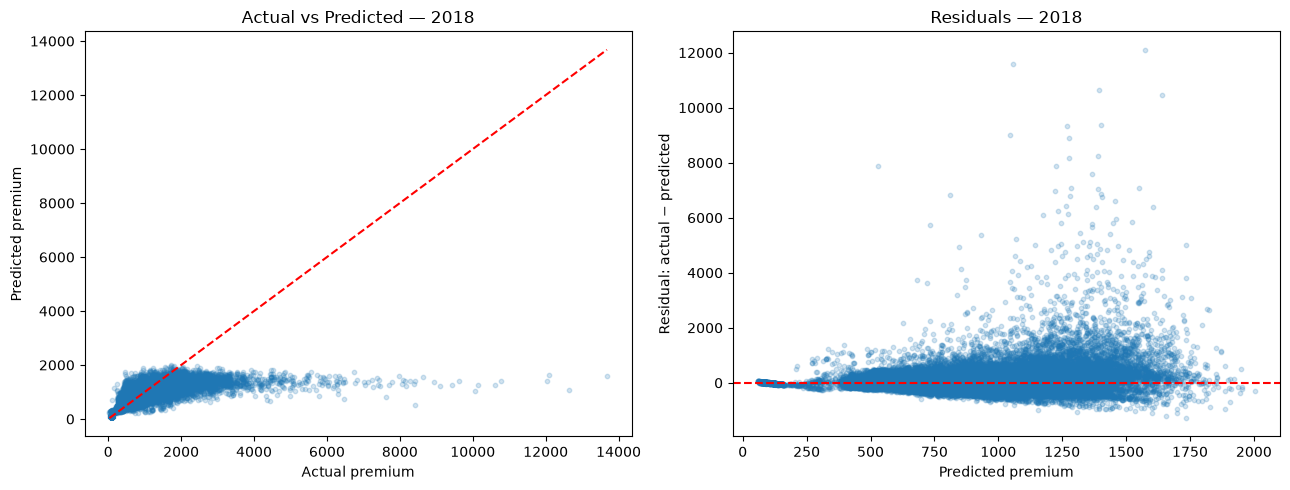

In [16]:
validation_results = pd.DataFrame({
    "actual_premium": y_val,
    "predicted_premium": val_predictions
})

# Positive residual means the model underpredicted.
validation_results["residual"] = (
    validation_results["actual_premium"]
    - validation_results["predicted_premium"]
)

validation_results["absolute_error"] = (
    validation_results["residual"].abs()
)

display(validation_results.head())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual versus predicted premiums.
axes[0].scatter(
    y_val, val_predictions,
    alpha=0.2, s=10
)

limits = [
    min(y_val.min(), val_predictions.min()),
    max(y_val.max(), val_predictions.max())
]

axes[0].plot(limits, limits, "r--")
axes[0].set_xlabel("Actual premium")
axes[0].set_ylabel("Predicted premium")
axes[0].set_title("Actual vs Predicted — 2018")

# Residuals versus predicted premiums.
axes[1].scatter(
    val_predictions,
    validation_results["residual"],
    alpha=0.2, s=10
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted premium")
axes[1].set_ylabel("Residual: actual − predicted")
axes[1].set_title("Residuals — 2018")

plt.tight_layout()
plt.show()

In [17]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train Ridge Regression.
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_processed, y_train_log)

# Predict on 2018 validation.
ridge_predictions_log = ridge_model.predict(X_val_processed)

# Convert predictions to original premium units.
ridge_predictions = np.exp(ridge_predictions_log)

# Evaluate.
mae = mean_absolute_error(y_val, ridge_predictions)
rmse = np.sqrt(mean_squared_error(y_val, ridge_predictions))
r2 = r2_score(y_val, ridge_predictions)

print("Ridge Regression — 2018 Validation")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

Ridge Regression — 2018 Validation
MAE:  224.90
RMSE: 431.66
R²:   0.4158


In [18]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

alphas = [0.01, 0.1, 1, 10, 100, 1000]

results = []
best_mae = np.inf

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_processed, y_train_log)

    # Convert log predictions to original premium units.
    train_predictions = np.exp(model.predict(X_train_processed))
    val_predictions = np.exp(model.predict(X_val_processed))

    train_mae = mean_absolute_error(y_train, train_predictions)
    val_mae = mean_absolute_error(y_val, val_predictions)

    results.append({
        "alpha": alpha,
        "train_MAE": train_mae,
        "val_MAE": val_mae,
        "train_RMSE": np.sqrt(
            mean_squared_error(y_train, train_predictions)
        ),
        "val_RMSE": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        ),
        "train_R2": r2_score(y_train, train_predictions),
        "val_R2": r2_score(y_val, val_predictions)
    })

    if val_mae < best_mae:
        best_mae = val_mae
        best_ridge = model
        best_alpha = alpha

ridge_results = pd.DataFrame(results).sort_values("val_MAE")

display(ridge_results.round(4))

print("Best alpha:", best_alpha)

print("\nSelected Ridge — Training and Validation")
display(
    ridge_results.loc[
        ridge_results["alpha"].eq(best_alpha)
    ].round(4)
)

,alpha,train_MAE,val_MAE,train_RMSE,val_RMSE,train_R2,val_R2
0,0.01,208.5987,224.8936,418.3620,431.6249,0.4226,0.4158
1,0.10,208.5995,224.8945,418.3654,431.6280,0.4225,0.4158
2,1.00,208.6087,224.9046,418.3993,431.6601,0.4225,0.4158
3,10.00,208.7454,225.0320,418.7739,432.0093,0.4214,0.4148
4,100.00,211.1679,226.8673,423.0391,435.8754,0.4096,0.4043
5,1000.00,223.1649,236.7485,440.0956,451.8167,0.3610,0.3599


Best alpha: 0.01

Selected Ridge — Training and Validation


,alpha,train_MAE,val_MAE,train_RMSE,val_RMSE,train_R2,val_R2
0,0.01,208.5987,224.8936,418.362,431.6249,0.4226,0.4158
